In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.datasets import make_blobs

In [ ]:
X, y = make_blobs(n_samples=50, centers=2)

In [ ]:
X

array([[ -5.92421757,   7.55910821],
       [  7.07988129, -10.31614684],
       [ -5.81115125,   8.38046222],
       [  7.39541478,  -8.75921452],
       [  4.72095031,  -8.62112073],
       [ -7.83126448,   6.74717821],
       [  6.09853614, -10.74823657],
       [  6.39398109, -10.56560886],
       [ -6.93920908,   7.15902709],
       [ -5.22086752,   8.50289   ],
       [ -7.25710571,   7.31124425],
       [ -5.22045585,   5.89012211],
       [ -5.9258677 ,   6.60008058],
       [  8.88519463,  -8.82377214],
       [  6.80305252,  -8.64005461],
       [  5.67755772,  -9.81267016],
       [ -6.90864351,   6.80708173],
       [  4.85826506,  -9.90717947],
       [  6.50577565, -10.68420989],
       [ -6.47198675,   6.19034152],
       [ -5.85269798,   7.36832746],
       [ -6.5731716 ,   7.55143171],
       [ -6.27126934,   7.14153146],
       [ -8.01969886,   6.04230546],
       [  6.89034608,  -9.83448114],
       [  7.53012158,  -8.9551134 ],
       [  5.9497544 ,  -9.79385575],
 

In [ ]:
y

array([0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 1])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42, test_size=0.3)

In [ ]:
X_train.shape

(35, 2)

In [ ]:
X_test.shape

(15, 2)

In [ ]:
clf = svm.SVC(kernel='linear', C=0.01, probability=True)
clf.fit(X_train, y_train)

SVC(C=0.01, kernel='linear', probability=True)

In [ ]:
y_pred = clf.predict(X_test)

In [ ]:
y_pred

array([1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0])

In [ ]:
y_test

array([1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0])

In [ ]:
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[8 0]
 [0 7]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00         7

    accuracy                           1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15



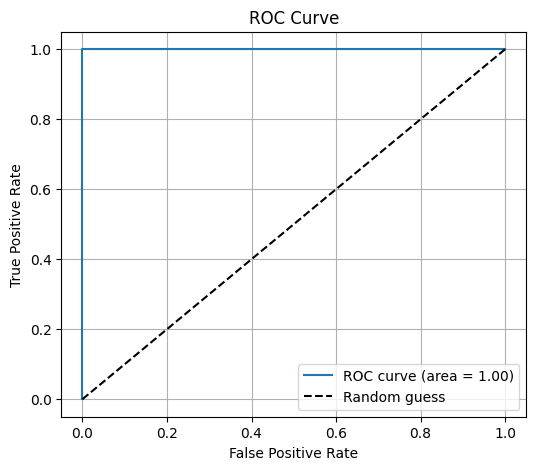

In [ ]:
y_score = clf.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
p

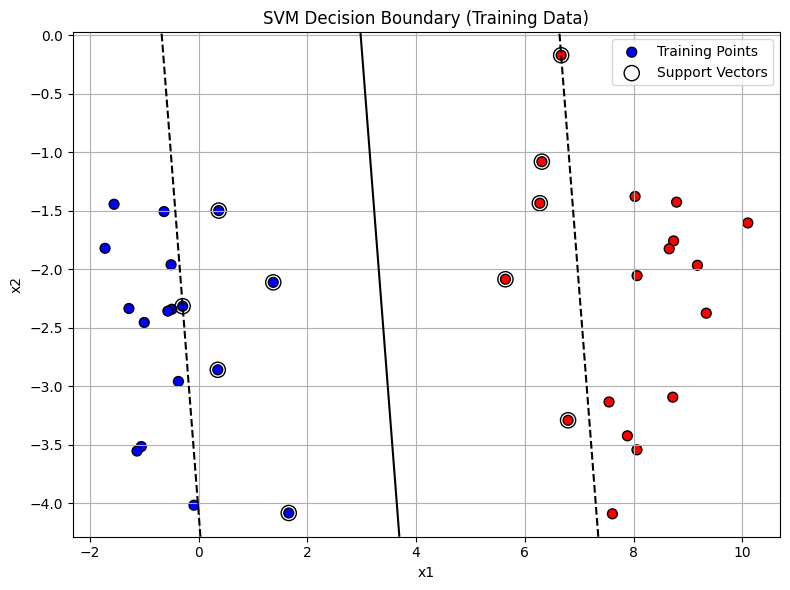

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='bwr', s=50, edgecolors='k', label='Training Points')

plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=120, facecolors='none', edgecolors='k', label='Support Vectors')

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 200)
yy = np.linspace(ylim[0], ylim[1], 200)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)

plt.contour(XX, YY, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors='k')

plt.title("SVM Decision Boundary (Training Data)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Enter value for feature x1: 5
Enter value for feature x2: 3
Predicted class for point (5.0, 3.0): 1


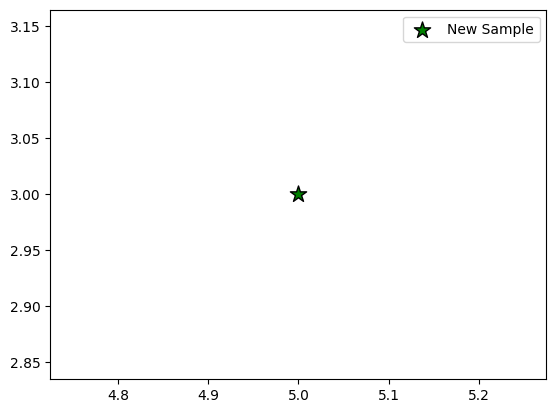

In [ ]:
x1 = float(input("Enter value for feature x1: "))
x2 = float(input("Enter value for feature x2: "))
new_point = np.array([[x1, x2]])

predicted_class = clf.predict(new_point)[0]
print(f"Predicted class for point ({x1}, {x2}): {predicted_class}")

plt.scatter(new_point[0, 0], new_point[0, 1], c='green', s=150,
            marker='*', edgecolors='k', label='New Sample')

plt.legend()
plt.show()

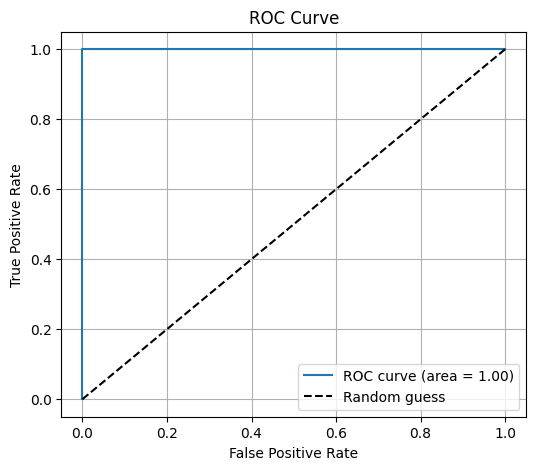

In [ ]:
from sklearn.metrics import roc_curve, auc

y_scores = clf.decision_function(X)
fpr, tpr, _ = roc_curve((y + 1) // 2, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd

heart_df = pd.read_csv('/content/heart.csv')

print(heart_df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/heart.csv'

In [ ]:
heart_df.shape

(303, 14)

In [ ]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = heart_df.drop(columns=['target'])
y = heart_df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42, test_size=0.2)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.svm import SVC

svm_clf = SVC(kernel='linear', C=1.0, random_state=42)

svm_clf.fit(X_train_scaled, y_train)

SVC(kernel='linear', random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = svm_clf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.7868852459016393
              precision    recall  f1-score   support

           0       0.86      0.64      0.73        28
           1       0.75      0.91      0.82        33

    accuracy                           0.79        61
   macro avg       0.80      0.78      0.78        61
weighted avg       0.80      0.79      0.78        61

Confusion Matrix:
 [[18 10]
 [ 3 30]]
